This script summarizes the inital work on the bound test from march, as this happend outside this repository. And not everything is needed for the thesis. 

In [1]:
import scvelo
import numpy as np
import torch
import yaml

import matplotlib as mpl
from matplotlib import pyplot as plt
import seaborn as sns
from tqdm import tqdm
import anndata as ad

from velotest.hypothesis_testing import run_hypothesis_test_on
from velotest.neighbors import find_neighbors_in_direction_of_velocity, find_neighbors

import scanpy as sc
from scipy.spatial import distance
from scipy import stats
from sklearn.metrics import mean_squared_error
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.colors import Normalize
from velotest.plotting import arrow_plot, plot_uniformity_histogram, plot_best_possible_velocities_statistic, compute_angle_on_gridplot_between

In [2]:
def plot_bounds(test_optimal, general_bound, bound_neighborhood, bound_optimal_emb, bound_optimal_emb_neighborhood,
                dataset_name, ax=None, legend=False, limits=None):
    if ax is None:
        _, ax = plt.subplots(constrained_layout=True)

    palette = sns.color_palette("colorblind", 5)
    ax.set_prop_cycle(color=palette)

    
    sns.kdeplot(general_bound, clip=(-1, 1), fill=False, label="General upper bound", color=palette[1],)  # max of all
    sns.kdeplot(bound_neighborhood, clip=(-1, 1), fill=False, color=palette[2],
                label="Upper bound assuming \nneighborhood embedding")  # mean over top k of all
    sns.kdeplot(test_optimal, clip=(-1, 1), fill=False, label="Test-optimal velocity \non original visualization", linestyle="--", color=palette[0],)
    #sns.kdeplot(bound_optimal_emb, clip=(-1, 1), fill=False,
    #            label="Upper bound assuming optimal \nneighborhood embedding")  # max of neighborhood
    #sns.kdeplot(bound_optimal_emb_neighborhood, clip=(-1, 1), fill=False, color=palette[2], linestyle='--',
    #            label="Upper bound assuming optimal \nneighborhood embedding and \nneighborhood sizes $s_i=10$")  # mean over top k of neighborhood

    ax.set_xlabel("Cosine similarity")
    ax.set_ylabel("Density")
    ax.legend(loc='upper left')
    if limits is not None:
        ax.set_xlim(limits)
    ax.yaxis.set_major_locator(mpl.ticker.MaxNLocator(integer=True, nbins=4))
    ax.xaxis.set_major_locator(mpl.ticker.MaxNLocator(integer=True, nbins=3))
    ax.set_title(dataset_name)

    #plt.savefig(f"fig/upper_bounds_{dataset_name}.pdf", transparent=True)
    return ax

In [3]:
def plot_embeddings(test_umap, test_tsne, test_pca, bound_optimal_emb,
                dataset_name, legend=False):
    
    _, ax = plt.subplots(constrained_layout=True)

    palette = sns.color_palette("colorblind", 5)
    ax.set_prop_cycle(color=palette)

    sns.kdeplot(bound_optimal_emb, clip=(-1, 1), fill=False, color=palette[2], 
                label="Upper bound assuming optimal \nneighborhood embedding")
    sns.kdeplot(test_umap, clip=(-1, 1), fill=False, color=palette[0], 
                label="Test-optimal velocity on \nUMAP visualization")
    sns.kdeplot(test_tsne, clip=(-1, 1), fill=False, color=palette[0], linestyle="--", 
                label="on TSNE visualization")
    sns.kdeplot(test_pca, clip=(-1, 1), fill=False, color=palette[0], linestyle=":", 
                label="on PCA visualization")
    

    ax.set_xlabel("Cosine similarity")
    ax.set_ylabel("Density")

    ax.legend(loc="upper left")
    
    ax.set_xlim(-1,1)
    ax.yaxis.set_major_locator(mpl.ticker.MaxNLocator(integer=True, nbins=4))
    ax.xaxis.set_major_locator(mpl.ticker.MaxNLocator(integer=True, nbins=3))
   
    #plt.savefig(f"velotest-bounds/notebooks/fig/embedding_bounds_{dataset_name}.pdf", transparent=True)
    return ax

In [4]:
def bestVelocityEmbedded(adata, basis, clusters, cluster_colors):
    Z_expr = f"X_{basis}"
    Z_velocity_vector = f"velocity_{basis}"
    uncorrected_p_values, h0_rejected, debug_dict = run_hypothesis_test_on(adata, basis=basis, number_neighbors_to_sample_from=200, null_distribution="velocities-explicit", cosine_empty_neighborhood=None, correction="bonferroni", restrict_to_velocity_genes=True, exclusion_degree=10)
    statistics = debug_dict['statistics']
    non_empty_neighborhoods_indices = np.where(uncorrected_p_values != 2)[0]

    # Calculate emmbeding test optimal statistic
    best_value = [statistics.get_max_value(offset=True)[1] for statistics in statistics if statistics is not None]

    best_possible_velocities = [statistic.get_max_value(offset=True)[0] for statistic in statistics if
                                    statistic is not None]
    best_velocity_range_mean = []
    for range_best in best_possible_velocities:
        best_velocity_range_mean.append((range_best[0] + range_best[1]) / 2)
    best_velocity_range_mean = np.array(best_velocity_range_mean)
    best_velocities = np.stack([np.cos(best_velocity_range_mean), np.sin(best_velocity_range_mean)], axis=-1)

    adata_best = adata.copy()
    adata_best.obsm[Z_velocity_vector] = np.zeros((adata.shape[0], 2))
    adata_best.obsm[Z_velocity_vector][non_empty_neighborhoods_indices] = best_velocities

    angles = compute_angle_on_gridplot_between(adata, adata_best, basis=basis)

    norm = Normalize(vmin=0, vmax=90)
    cmap = LinearSegmentedColormap.from_list("lightgrey_to_black", ["#eeefff", "#000000"])
    sm = mpl.cm.ScalarMappable(cmap=cmap, norm=norm)
    colors = sm.to_rgba(angles)

    adata_plotting = ad.AnnData(adata_best.X, obs=adata_best.obs.copy())
    adata_plotting.obsm[Z_expr] = adata_best.obsm[Z_expr]
    adata_plotting.obsm[Z_velocity_vector] = adata_best.obsm[Z_velocity_vector]
    adata_plotting.layers['velocity'] = adata_best.layers['velocity']
    adata_plotting.uns[cluster_colors] = adata_best.uns[cluster_colors]
    color_dict_plotting = dict(zip(adata_plotting.obs[clusters].cat.categories,
                                    adata_plotting.uns[cluster_colors]))

    return adata_plotting

In [ ]:
datasets = {
        "Pancreas_dynamical": "../configs/pancreas_dynamic.yaml",
        #"Pancreas_stochastic": "../configs/pancreas_stochastic.yaml",
        #"Dentate_gyrus": "../configs/dentategyrus.yaml",
        "Gastrulation_erythroid": "../configs/gastrulation.yaml",
        #"Bone_marrow": "../configs/bonemarrow.yaml",
        "PBMC": "../configs/pbmc.yaml",
        #"Covid": "../configs/covid.yaml",
        "Retinal_development": "../configs/retinal_development.yaml",
        #"Human_HSC": "../configs/humanHSC.yaml",
        #"Intestinal_development": "../configs/noEmbedding/intestinal_organoids.yaml",
        #"Hindbrain_mouse": "../configs/noEmbedding/hindbrain.yaml",
        #"Oligodendrocyte_mouse": "../configs/noEmbedding/oligodendrocyte.yaml",
        #"Bone_marrow_mouse": "../configs/noEmbedding/mouse_bonemarrow.yaml",
        #"Cerebral_cortex_human": "../configs/noEmbedding/human_cerebral.yaml",
        #"Hematopoiesis_mouse": "../configs/noEmbedding/mouse_hema.yaml",
        #"Spermatogenisis": "../configs/noEmbedding/spermatogenesis.yaml",
        #"Old_brain": "../configs/noEmbedding/old_brain.yaml",
        #"Prefrontal_cortex": "../configs/noEmbedding/pfc.yaml",
        #"Intestinal_organoids":"../configs/noEmbedding/GSE128365.yaml"
    }

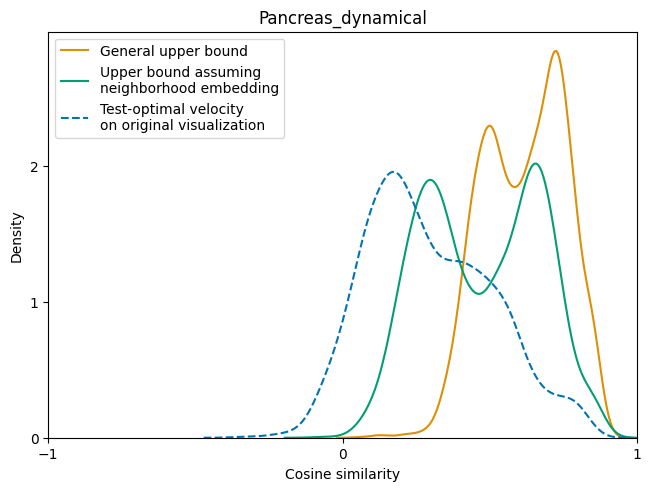

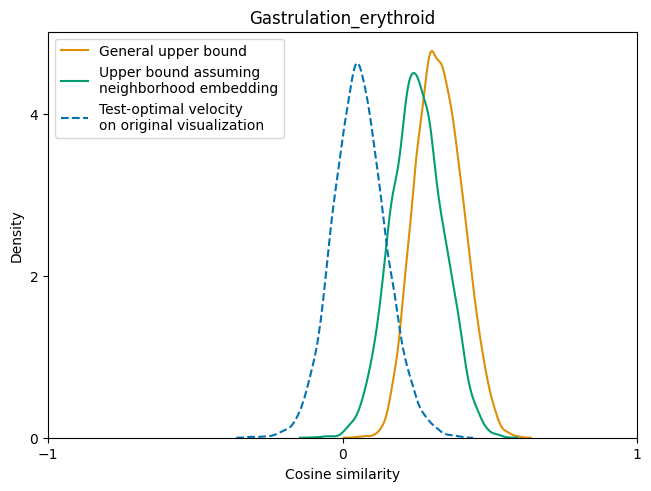

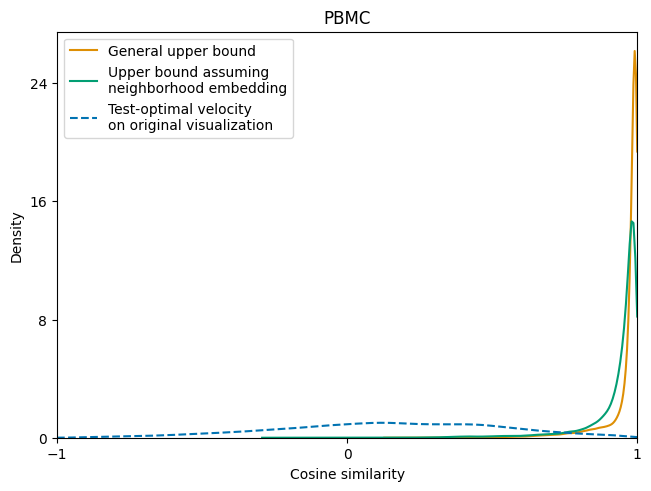

In [ ]:
for name, path in datasets.items():
    with open(path, "r") as f:
            config = yaml.safe_load(f)
   
    adata = sc.read(config["path"]) 
    general = adata.obsm['general_bound']
    upper = adata.obsm['upper_max_neighbors'] 
    best = adata.uns['best_embedding']
    plot_bounds(best, general, upper, best, best, name, limits=(-1, 1))

computing velocity embedding
    finished (0:00:00) --> added
    'velocity_tsne', embedded velocity vectors (adata.obsm)
computing velocity embedding
    finished (0:00:00) --> added
    'velocity_pca', embedded velocity vectors (adata.obsm)
Dropping all the genes which are not velocity genes. 1027 genes left.
Number of workers:  9
Runnining with new modification


100%|██████████| 3696/3696 [00:36<00:00, 102.57it/s]


Dropping all the genes which are not velocity genes. 1027 genes left.
Number of workers:  9
Runnining with new modification


100%|██████████| 3696/3696 [00:37<00:00, 99.42it/s] 


computing velocity embedding
    finished (0:00:01) --> added
    'velocity_tsne', embedded velocity vectors (adata.obsm)
computing velocity embedding
    finished (0:00:02) --> added
    'velocity_pca', embedded velocity vectors (adata.obsm)
Dropping all the genes which are not velocity genes. 488 genes left.
Number of workers:  9
Runnining with new modification


...

100%|██████████| 65877/65877 [19:33<00:00, 56.12it/s]  


computing velocity embedding
    finished (0:00:00) --> added
    'velocity_tsne', embedded velocity vectors (adata.obsm)
computing velocity embedding
    finished (0:00:00) --> added
    'velocity_pca', embedded velocity vectors (adata.obsm)
Dropping all the genes which are not velocity genes. 677 genes left.
Number of workers:  9
Runnining with new modification


100%|██████████| 2726/2726 [00:27<00:00, 100.38it/s]


Dropping all the genes which are not velocity genes. 677 genes left.
Number of workers:  9
Runnining with new modification


100%|██████████| 2726/2726 [00:27<00:00, 98.76it/s] 


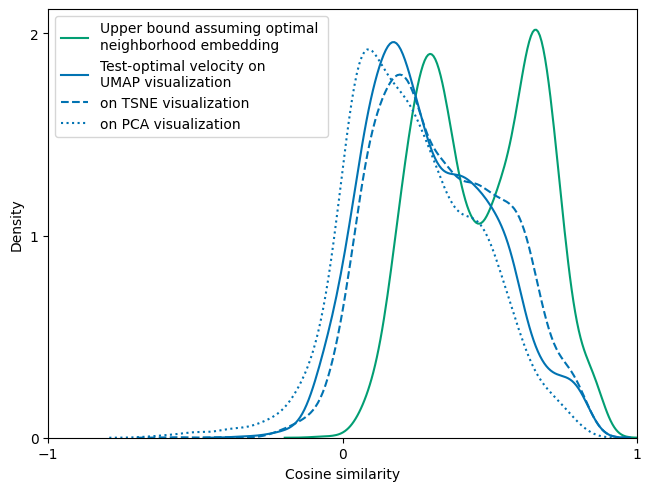

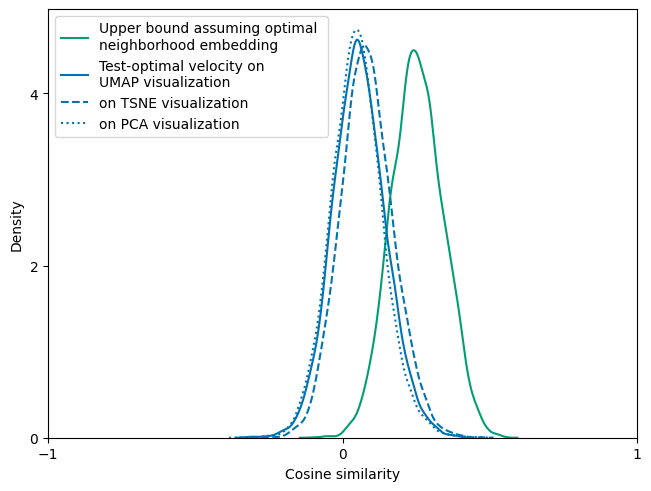

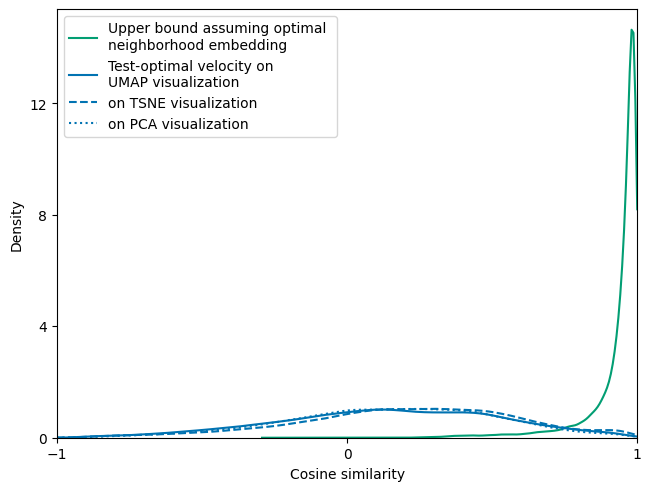

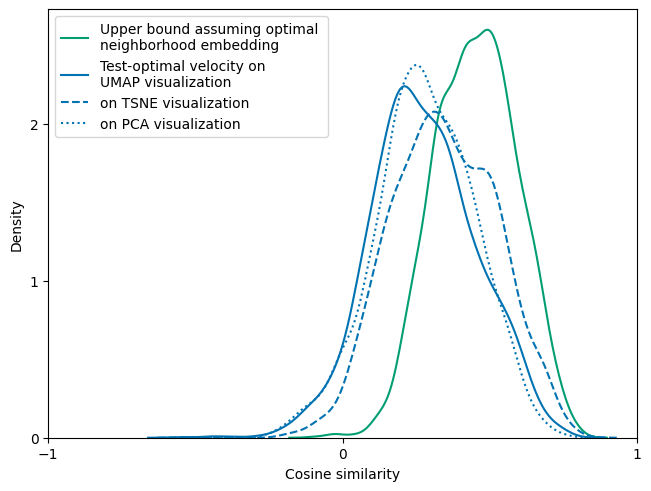

In [6]:
for name, path in datasets.items():
    with open(path, "r") as f:
            config = yaml.safe_load(f)
   
    adata = sc.read(config["path"]) 
    general = adata.obsm['general_bound']
    upper = adata.obsm['upper_max_neighbors'] 
    best = adata.uns['best_embedding']
    # Get tsne
    sc.tl.tsne(adata)
    scvelo.tl.velocity_embedding(adata, basis='tsne')
    scvelo.tl.velocity_embedding(adata, basis='pca')
    uncorrected_p_values, h0_rejected, debug_dict = run_hypothesis_test_on(adata, basis="tsne", number_neighbors_to_sample_from=300, null_distribution="velocities-explicit", cosine_empty_neighborhood=None, correction="bonferroni", restrict_to_velocity_genes=True, exclusion_degree=10)
    statistics = debug_dict['statistics']
    tsne = [statistics.get_max_value(offset=True)[1] for statistics in statistics if statistics is not None]

    # get pca
    adata.obsm['X_pca'] = adata.obsm['X_pca'][:, :2]
    adata.obsm['velocity_pca'] = adata.obsm['velocity_pca'][:, :2]
    uncorrected_p_values, h0_rejected, debug_dict = run_hypothesis_test_on(adata, basis="pca", number_neighbors_to_sample_from=300, null_distribution="velocities-explicit", cosine_empty_neighborhood=None, correction="bonferroni", restrict_to_velocity_genes=True, exclusion_degree=10)
    statistics = debug_dict['statistics']
    pca = [statistics.get_max_value(offset=True)[1] for statistics in statistics if statistics is not None]

    plot_embeddings(best, tsne, pca, upper, name)

Dropping all the genes which are not velocity genes. 1027 genes left.
Number of workers:  9
Runnining with new modification


100%|██████████| 3696/3696 [00:24<00:00, 153.24it/s]


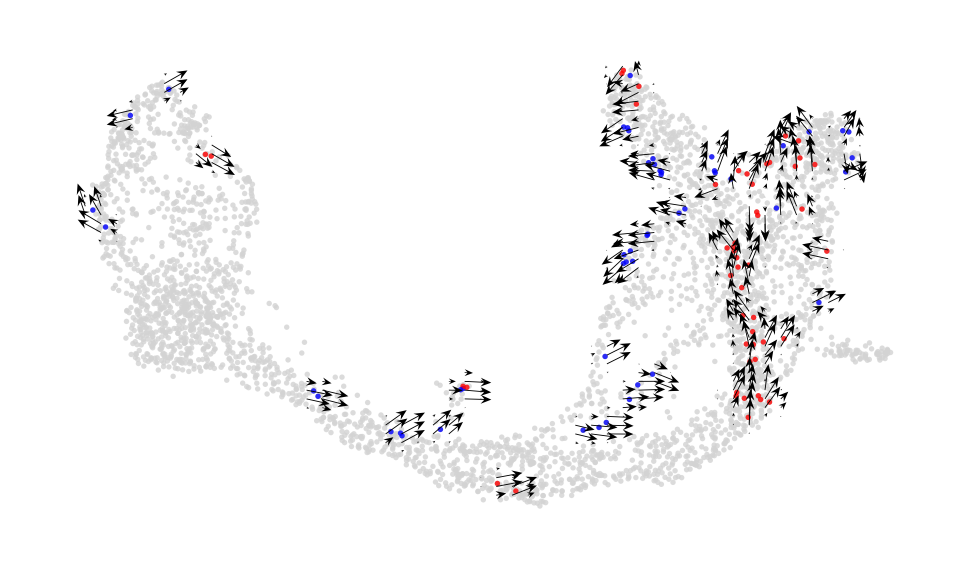

Dropping all the genes which are not velocity genes. 488 genes left.
Number of workers:  9
Runnining with new modification


100%|██████████| 9815/9815 [01:02<00:00, 156.08it/s]


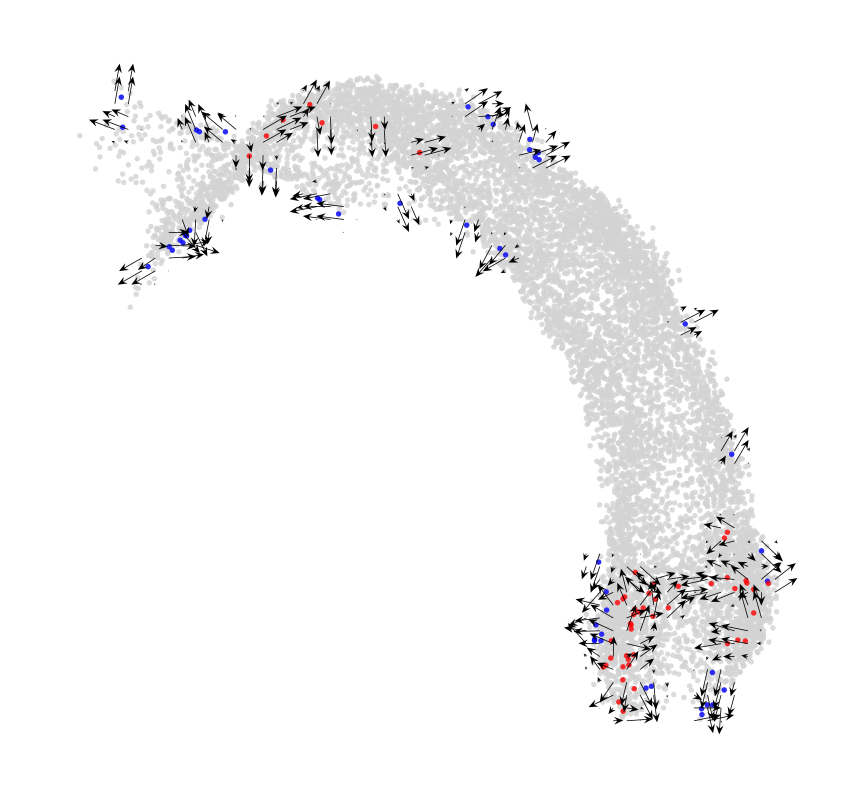

Dropping all the genes which are not velocity genes. 12 genes left.
Number of workers:  9
Runnining with new modification


100%|██████████| 65877/65877 [13:09<00:00, 83.46it/s] 


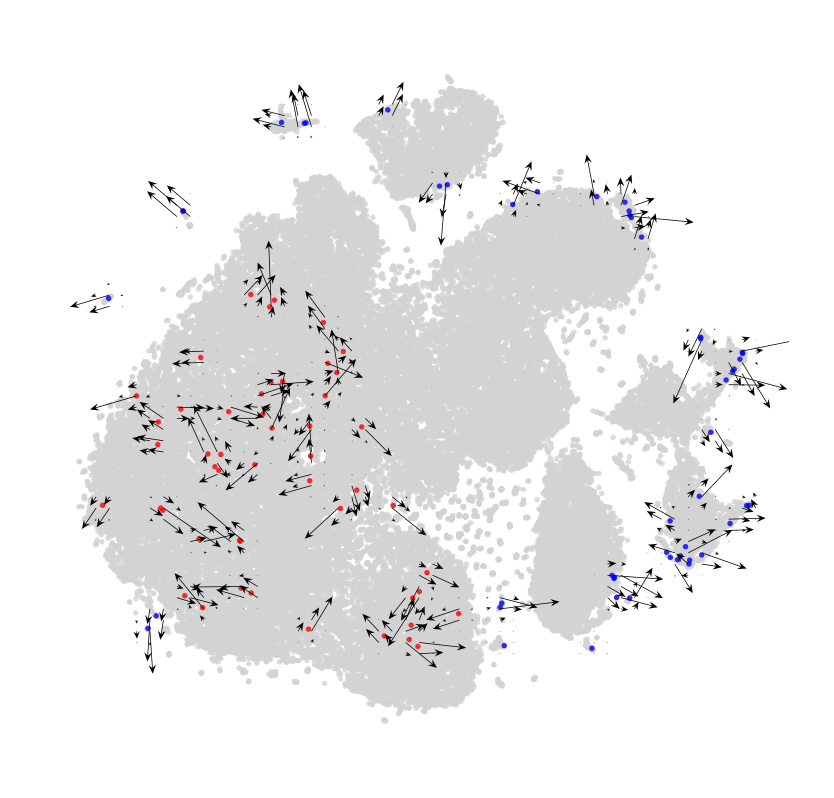

Dropping all the genes which are not velocity genes. 677 genes left.
Number of workers:  9
Runnining with new modification


100%|██████████| 2726/2726 [00:18<00:00, 147.61it/s]


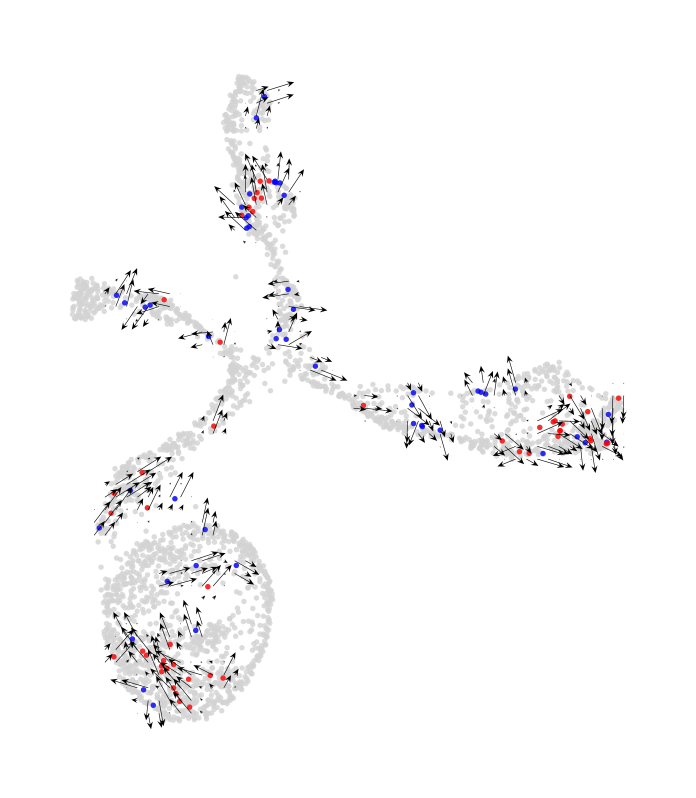

In [61]:
for name, path in datasets.items():
    with open(path, "r") as f:
        config = yaml.safe_load(f)

    adata = sc.read(config["path"]) 
    basis = config["basis"]
    clusters = config["cluster"]
    cluster_colors = config["cluster_colors"]
    general = adata.obsm['general_bound']
    upper = adata.obsm['upper_max_neighbors'] 
    best = adata.uns['best_embedding']
    non_empty_indices = adata.uns['non_empty_indices']
    upper_n = upper[non_empty_indices]

    dis = np.square(np.subtract(best,upper_n))
    high_indices = np.argpartition(dis, -50)[-50:]
    low_indices = np.argpartition(dis, 50)[:50]
    adata.obs['highlight'] = 'Other'
    subset_barcodes = adata.obs.index[non_empty_indices]

    high_barcodes = subset_barcodes[high_indices]
    low_barcodes = subset_barcodes[low_indices]
    adata.obs.loc[high_barcodes, 'highlight'] = 'Target Cells'
    adata.obs.loc[low_barcodes, 'highlight'] = 'Low Cells'
    adata_plot = bestVelocityEmbedded(adata, basis=basis, clusters=clusters, cluster_colors=cluster_colors)

    # Plotting
    cm = 1 / 2.54 
    figsize=(5 * cm, 4 * cm)
    fig, ax = plt.subplots(dpi=450, figsize=figsize)
    ax.set(xticks=[], yticks=[])
    pl = scvelo.pl.velocity_embedding_grid(adata_plot, 
                                    basis=basis, 
                                    color='highlight', 
                                    groups=['Target Cells', 'Low Cells'], 
                                    palette={'Target Cells': 'red', 'Other': 'lightgrey', 'Low Cells': 'blue'},
                                    show=False, size=3,rasterized=True, figsize=figsize,alpha=0.8,
                                    ax=ax, frameon=False, xlabel='', ylabel='', title ='',
                                    arrow_color='black', edgecolors=None,
                                    linewidth=.25, arrow_size=2, arrow_length=2, )
    ax.set_aspect('equal')
    fig.subplots_adjust(left=0, right=1, top=1, bottom=0)
    pl.set_rasterized(True)
    plt.savefig(f"/mnt/volume/Johanna_Velotest/results/bounds/{name}_highlighted_cells.pdf", transparent=True, dpi=450)
    plt.show()

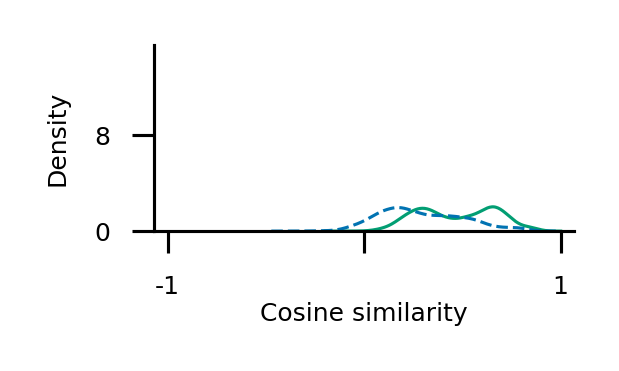

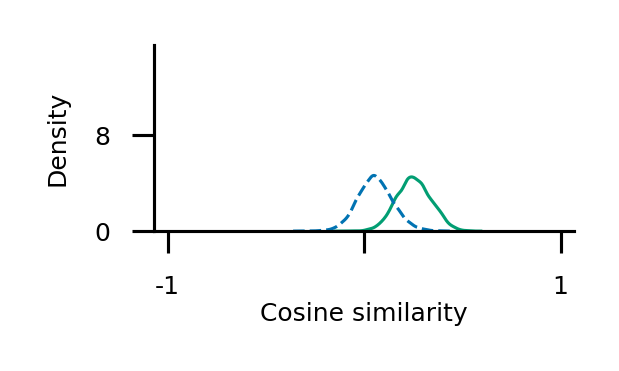

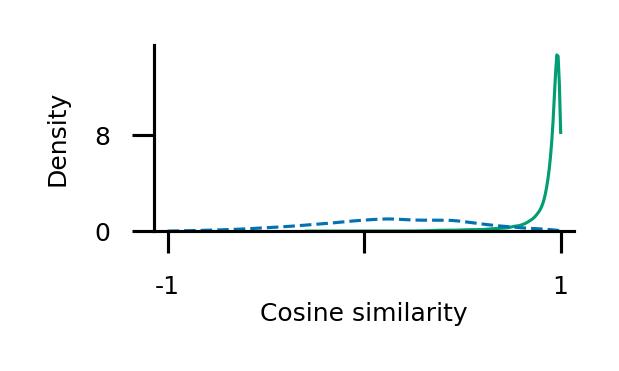

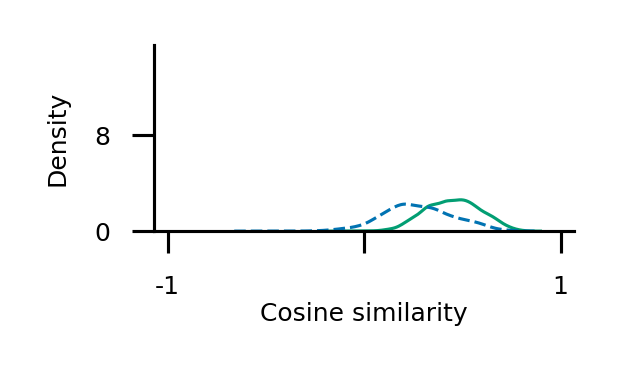

In [71]:
for name, path in datasets.items():
    with open(path, "r") as f:
        config = yaml.safe_load(f)

    adata = sc.read(config["path"]) 
    basis = config["basis"]
    clusters = config["cluster"]
    cluster_colors = config["cluster_colors"]
    general = adata.obsm['general_bound']
    upper = adata.obsm['upper_max_neighbors'] 
    best = adata.uns['best_embedding']
    non_empty_indices = adata.uns['non_empty_indices']
    upper_n = upper[non_empty_indices]



    cm = 1 / 2.54 
    figsize=(3.2 * cm, 1.8 * cm)
    fig, ax = plt.subplots(dpi=450, constrained_layout=True, figsize=figsize)
    palette = sns.color_palette("colorblind", 5)
    ax.set_prop_cycle(color=palette)

    sns.kdeplot(upper, clip=(-1, 1), fill=False, color=palette[2], label="Upper bound assuming \nneighborhood embedding", linewidth=0.5)  # mean over top k of all
    sns.kdeplot(best, clip=(-1, 1), fill=False, label="Test-optimal velocity \non original visualization", linestyle="--", color=palette[0], linewidth=0.5)
    ax.xaxis.set_major_locator(plt.MaxNLocator(3))

    ax.set_xticks([-1, 0, 1], labels=[-1, "", 1], fontsize=4)
    ax.tick_params(axis='both', width=0.5, labelsize=4)
    ax.yaxis.set_major_locator(plt.MaxNLocator(2))

    ax.spines["left"].set_linewidth(0.5)
    ax.spines["bottom"].set_linewidth(0.5)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    plt.xlim(-1.07, 1.07)

    plt.ylim(top=15.5)
    plt.xlabel("Cosine similarity", fontsize=4, labelpad=0.5)
    plt.ylabel("Density", fontsize=4)
    plt.savefig(f"/mnt/volume/Johanna_Velotest/results/bounds/{name}_{basis}_bound.pdf", transparent=True, dpi=450)

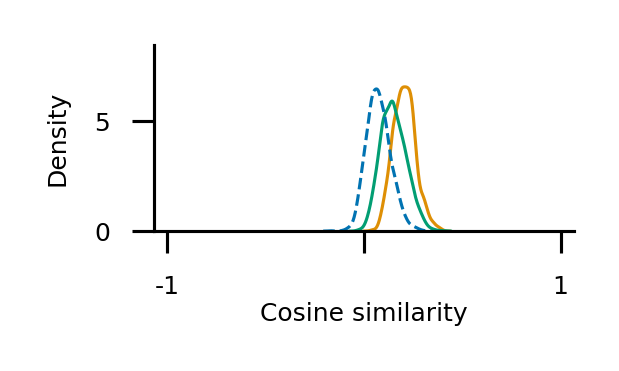

In [18]:

adata = sc.read("/mnt/volume/Johanna_Velotest/sim_data/dynamical_linear_2000_cells_500_genes_350_total_80_points_seed_42.h5ad") 
general = adata.obsm['general_bound']
upper = adata.obsm['upper_max_neighbors'] 
best = adata.uns['best_embedding']
non_empty_indices = adata.uns['non_empty_indices']
upper_n = upper[non_empty_indices]

cm = 1 / 2.54 
figsize=(3.2 * cm, 1.8 * cm)
fig, ax = plt.subplots(dpi=450, constrained_layout=True, figsize=figsize)
palette = sns.color_palette("colorblind", 5)
ax.set_prop_cycle(color=palette)

sns.kdeplot(general, clip=(-1, 1), fill=False, label="General upper bound", color=palette[1],linewidth=0.5)
sns.kdeplot(upper, clip=(-1, 1), fill=False, color=palette[2], label="Upper bound assuming \nneighborhood embedding", linewidth=0.5)  # mean over top k of all
sns.kdeplot(best, clip=(-1, 1), fill=False, label="Test-optimal velocity \non original visualization", linestyle="--", color=palette[0], linewidth=0.5)
ax.xaxis.set_major_locator(plt.MaxNLocator(3))

ax.set_xticks([-1, 0, 1], labels=[-1, "", 1], fontsize=4)
ax.tick_params(axis='both', width=0.5, labelsize=4)
ax.yaxis.set_major_locator(plt.MaxNLocator(2))

ax.spines["left"].set_linewidth(0.5)
ax.spines["bottom"].set_linewidth(0.5)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
plt.xlim(-1.07, 1.07)

plt.ylim(top=8.5)
plt.xlabel("Cosine similarity", fontsize=4, labelpad=0.5)
plt.ylabel("Density", fontsize=4)
plt.savefig("/mnt/volume/Johanna_Velotest/results/bounds/Dyngen_Seed42_bound.pdf", transparent=True, dpi=450)